# **Data exploration**

**Specialication:** Digital Environment  
**Authors:** Florian Klaver, Nicola Noger  
**Supervisor:** Martin Schüle  
**Submission Deadline:** 22.05.2025


---
## **Introduction**

The Goal of this project is to develop a Deep learning Model that can classify 3D LiDAR data based on several features. Then the model is deployed on the City-centers of the top five municipalities of the canton zurich with the most residents. The data used to train, test and deploy the model on was all collected from "Geoportal Kanton Zürich", the official source for geodata from the canton zurich. In this Jupyter Notebook, the data of one .laz-file was explored to get a general overview of how the data is structured.

### **Features**
| Field               | Description |
|---------------------|------------|
| **X**              | X coordinate (East-West) in projected coordinate system. |
| **Y**              | Y coordinate (North-South) in projected coordinate system. |
| **Z**              | Elevation (height) above a reference surface. |
| **intensity**      | Strength of the laser return signal. |
| **return_number**  | Order of the return (e.g., first, second, etc.). |
| **number_of_returns** | Total number of returns for a given laser pulse. |
| **synthetic**      | Flag indicating if the point was generated artificially. |
| **key_point**      | Flag for important points (e.g., survey control points). |
| **withheld**       | Flag for points that should be ignored (e.g., noise). |
| **overlap**        | overlap with neighbouring tiles|
| **scanner_channel** | Channel of the scanenr (1 or 2) |
| **scan_direction_flag** | Indicates scanning direction (0 = forward, 1 = backward). |
| **edge_of_flight_line** | Marks if a point is at the edge of a flight path. |
| **user_data**      | Custom field for additional information. |
| **scan_angle** | Angle of the laser scan. |
| **point_source_id** | Identifier for the source of the point (e.g., flight line). |
| **gps_time**       | Timestamp of when the point was captured. |
| **classification** | Category of the point. <br> <br> **1**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Unclassified (e.g. temporary objects such as cars)  <br> **2**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Ground  <br> **3**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Low vegetation (<.5m) <br> **4**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Medium vegetation (0.5m - 3m) <br> **5**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= High vegetation (>3m) <br> **6**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Building  <br> **7**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Errorclass/false measurements <br> **15**&nbsp;&nbsp;&nbsp;= High-voltage power lines and antennas  <br>**17**&nbsp;&nbsp;&nbsp;= Bridge  |




---
## **Setup**

In [13]:
# All imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import laspy
import tensorflow as tf
from sklearn.ensemble import RandomForestClassifier
import open3d as o3d

# Enable vectorized graphics
%config InlineBackend.figure_formats = ["svg"]

# Set seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

---
## **Numerical data exploration and analysis**

Each data file covering an area 500m x 500m consists of Millions of points (~6-9 Million). Here for the data exploration we only show the content of 1 file to safe computational expenses. For the real data preprocessing and training multiple files were used.

#### Load the data

In [14]:
path = "C:/Users/flori/Desktop/pa-1_data/training/2672500_1252000.laz"

las = laspy.read(path)

# List all available attributes in the LAS file
print("Available attributes in LAZ file:")
for spec in las.point_format.dimension_names:
    print("-", spec)


# total number of points
n_points = len(las.points)
print("\nTotal number of points:", n_points)

print(las.header)
print(las.points)

Available attributes in LAZ file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points: 7607751
<LasHeader(1.4, <PointFormat(6, 0 bytes of extra dims)>)>
<ScaleAwarePointRecord(fmt: <PointFormat(6, 0 bytes of extra dims)>, len: 7607751, point size: 30)>


In [15]:
# Inforamtion for transforming the data into a pandas dataframe
print(type(las.x)) 
print(type(las.x[0])) 

<class 'laspy.point.dims.ScaledArrayView'>
<class 'numpy.float64'>


In [16]:
# Create a pandas DataFrame with the LAZ data for initial data exploration
df = pd.DataFrame({
    "X": np.array(las.x), 
    "Y": np.array(las.y),
    "Z": np.array(las.z),
    "intensity": np.array(las.intensity),
    "return_number": np.array(las.return_number),
    "number_of_returns": np.array(las.number_of_returns),
    "synthetic": np.array(las.synthetic),
    "key_point": np.array(las.key_point),
    "withheld": np.array(las.withheld),
    "overlap": np.array(las.overlap),
    "scanner_channel": np.array(las.scanner_channel),
    "scan_direction_flag": np.array(las.scan_direction_flag),
    "edge_of_flight_line": np.array(las.edge_of_flight_line),
    "user_data": np.array(las.user_data),
    "scan_angle": np.array(las.scan_angle),
    "point_source_id": np.array(las.point_source_id),
    "gps_time": np.array(las.gps_time),
    "classification": np.array(las.classification)
})


# get a first impression of the data
print(df.shape)
display(df.info())
display(df.describe())
display(df.head())
print("\nClassification values:")
display(df["classification"].value_counts())

(7607751, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7607751 entries, 0 to 7607750
Data columns (total 18 columns):
 #   Column               Dtype  
---  ------               -----  
 0   X                    float64
 1   Y                    float64
 2   Z                    float64
 3   intensity            uint16 
 4   return_number        uint8  
 5   number_of_returns    uint8  
 6   synthetic            uint8  
 7   key_point            uint8  
 8   withheld             uint8  
 9   overlap              uint8  
 10  scanner_channel      uint8  
 11  scan_direction_flag  uint8  
 12  edge_of_flight_line  uint8  
 13  user_data            uint8  
 14  scan_angle           int16  
 15  point_source_id      uint16 
 16  gps_time             float64
 17  classification       uint8  
dtypes: float64(4), int16(1), uint16(2), uint8(11)
memory usage: 355.5 MB


None

,X,Y,Z,intensity,return_number,number_of_returns,synthetic,key_point,withheld,overlap,scanner_channel,scan_direction_flag,edge_of_flight_line,user_data,scan_angle,point_source_id,gps_time,classification
count,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06,7607751.0,7607751.0,7607751.0,7607751.0,7.607751e+06,7607751.0,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06,7.607751e+06
mean,2.672754e+06,1.252217e+06,3.876023e+02,4.209066e+04,1.245243e+00,1.489871e+00,0.0,0.0,0.0,0.0,1.489729e+00,0.0,9.858367e-06,1.489729e+00,1.451359e+03,3.429615e+01,4.824556e+04,3.373355e+00
std,1.387966e+02,1.459193e+02,8.455022e+00,7.815609e+03,5.395420e-01,7.535638e-01,0.0,0.0,0.0,0.0,4.998945e-01,0.0,3.139788e-03,4.998945e-01,1.106392e+03,4.606501e-01,1.159506e+04,1.777509e+00
min,2.672500e+06,1.252000e+06,3.751020e+02,2.389800e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,-4.833000e+03,3.300000e+01,4.743265e+04,1.000000e+00
25%,2.672638e+06,1.252089e+06,3.818800e+02,3.641500e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,5.000000e+02,3.400000e+01,4.743802e+04,2.000000e+00
50%,2.672761e+06,1.252195e+06,3.839630e+02,4.314300e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,1.667000e+03,3.400000e+01,4.744059e+04,2.000000e+00
75%,2.672869e+06,1.252341e+06,3.918770e+02,4.832100e+04,1.000000e+00,2.000000e+00,0.0,0.0,0.0,0.0,2.000000e+00,0.0,0.000000e+00,2.000000e+00,2.333000e+03,3.500000e+01,4.845435e+04,5.000000e+00
max,2.673000e+06,1.252500e+06,5.081680e+02,6.553500e+04,7.000000e+00,7.000000e+00,0.0,0.0,0.0,0.0,2.000000e+00,0.0,1.000000e+00,2.000000e+00,4.833000e+03,3.500000e+01,3.153969e+05,1.700000e+01


,X,Y,Z,intensity,return_number,number_of_returns,synthetic,key_point,withheld,overlap,scanner_channel,scan_direction_flag,edge_of_flight_line,user_data,scan_angle,point_source_id,gps_time,classification
0,2672500.016,1252248.682,384.670,40282,1,1,0,0,0,0,1,0,0,1,-4667,33,315389.921915,2
1,2672500.052,1252248.280,384.645,39473,1,1,0,0,0,0,1,0,0,1,-4667,33,315389.921915,2
2,2672500.085,1252247.883,384.630,43799,1,1,0,0,0,0,1,0,0,1,-4667,33,315389.921916,2
3,2672500.061,1252254.152,384.688,43384,1,1,0,0,0,0,1,0,0,1,-4667,33,315389.916365,2
4,2672500.457,1252249.536,384.709,40194,1,1,0,0,0,0,1,0,0,1,-4667,33,315389.916374,2



Classification values:


classification
2     4283120
6     1354491
5     1325875
4      384870
3      132850
1      100109
7       14522
17      11291
15        623
Name: count, dtype: int64

In [17]:
# check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# check for duplicates
print("\nDuplicates:")
print(df.duplicated().sum())


Missing values:
X                      0
Y                      0
Z                      0
intensity              0
return_number          0
number_of_returns      0
synthetic              0
key_point              0
withheld               0
overlap                0
scanner_channel        0
scan_direction_flag    0
edge_of_flight_line    0
user_data              0
scan_angle             0
point_source_id        0
gps_time               0
classification         0
dtype: int64

Duplicates:
0


In [18]:
# check for the number of unique values in each column
print(df.nunique())

X                       499964
Y                       499999
Z                        48678
intensity                 1903
return_number                7
number_of_returns            7
synthetic                    1
key_point                    1
withheld                     1
overlap                      1
scanner_channel              2
scan_direction_flag          1
edge_of_flight_line          2
user_data                    2
scan_angle                  45
point_source_id              3
gps_time               6114910
classification               9
dtype: int64


In [19]:
# Columns with very few unique values can already be dropped sice they do not add any information to the model.
df = df.loc[:, df.nunique() > 4]
print("\nDataFrame after dropping columns with only one unique value:")
display(df.info())

# gps_time most likely also does not add any information to the model.
# We will keep it for now and confirm this assumption later in the analysis.


DataFrame after dropping columns with only one unique value:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7607751 entries, 0 to 7607750
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   X                  float64
 1   Y                  float64
 2   Z                  float64
 3   intensity          uint16 
 4   return_number      uint8  
 5   number_of_returns  uint8  
 6   scan_angle         int16  
 7   gps_time           float64
 8   classification     uint8  
dtypes: float64(4), int16(1), uint16(1), uint8(3)
memory usage: 283.0 MB


None

---
## **Visual data exploration and analysis**

#### Class distribution

In [20]:
features = df.drop(columns=["classification"])

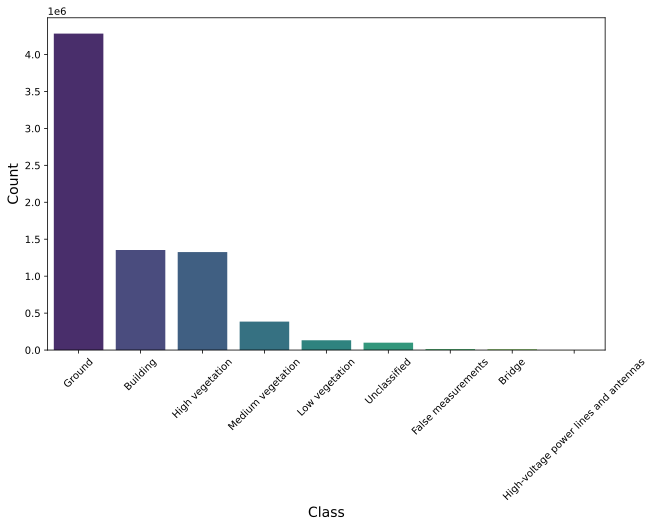

In [23]:
# Define class labels
class_labels = {
    1: "Unclassified",
    2: "Ground",
    3: "Low vegetation",
    4: "Medium vegetation",
    5: "High vegetation",
    6: "Building",
    7: "False measurements",
    15: "High-voltage power lines and antennas",
    17: "Bridge"
}

class_counts = df["classification"].value_counts()
class_labels_mapped = class_counts.index.map(class_labels).fillna("Other")

# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_labels_mapped, y=class_counts.values, hue=class_labels_mapped, palette="viridis")
#plt.title("Class Distribution", fontsize=16)
plt.xlabel("Class", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks(rotation=45)
plt.show()

#### Histogram

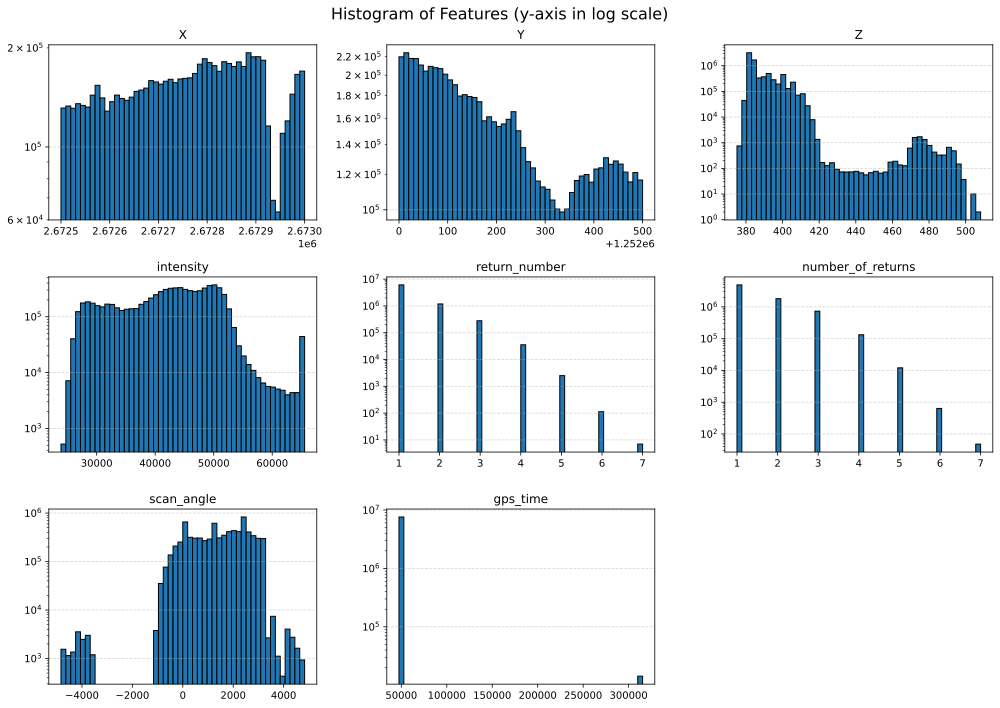

In [10]:
axes = features.hist(figsize=(14, 10), bins=50, edgecolor='black')  
plt.suptitle("Histogram of Features (y-axis in log scale)", fontsize=16)

# Convert axes to a flat list (in case of multiple rows)
axes = axes.flatten()

# Disable x-axis grid and enable y-axis grid
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.grid(False, axis='x')
    ax.set_yscale("log")

plt.tight_layout()
plt.show()

#### Correlation-matrix

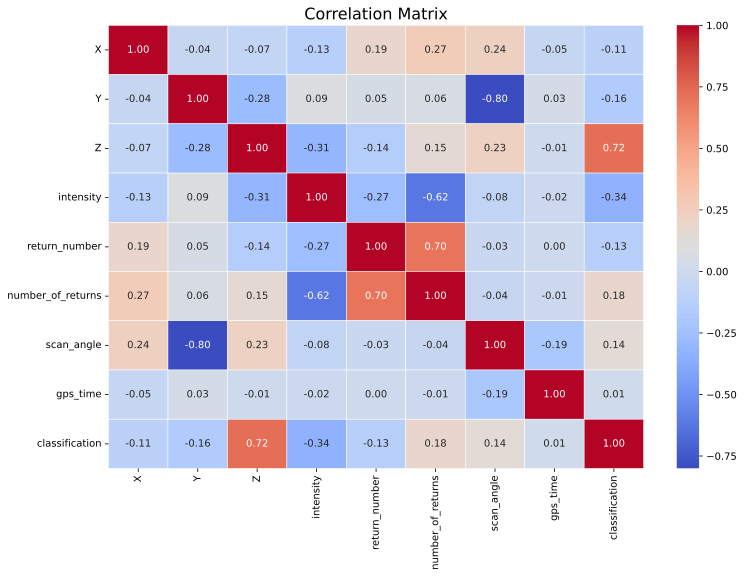

classification       1.000000
Z                    0.723630
number_of_returns    0.178678
scan_angle           0.135836
gps_time             0.012475
X                   -0.110031
return_number       -0.128130
Y                   -0.164315
intensity           -0.336404
Name: classification, dtype: float64

In [11]:
corr = df.corr()
f, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", annot=True, linewidths=0.5, fmt=".2f", ax=ax)
plt.title("Correlation Matrix", fontsize=16)
plt.show()

# print correlation values for classification
display(corr['classification'].sort_values(ascending=False))

#### Feature Importance

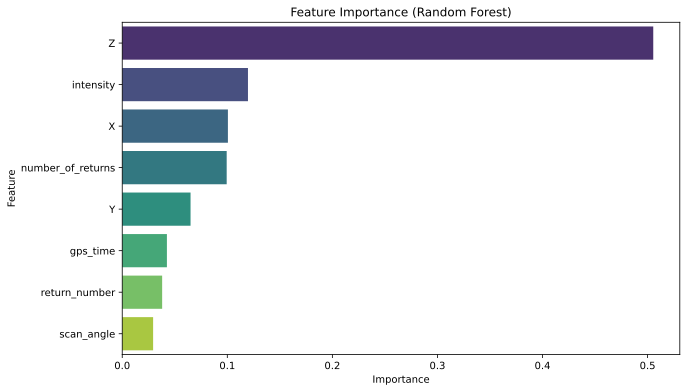

In [12]:
# define features and target
X = df.drop(columns=['classification'])
y = df['classification']

# train random forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

# extract feature importances
importances = rf.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Random Forest)')
plt.show()

#### Visualize 3D points with open3d

In [25]:
# -- Colour point cloud based on height --
points = np.vstack((las.x, las.y, las.z)).transpose()
# Create Open3D point cloud object
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)

# Visualize
o3d.visualization.draw_geometries([pcd])

In [ ]:
# -- colour point cloud based on classification --

# Extract classification labels
labels = las.classification

# Define a color mapping for different classes
color_map = {
    1: [0.6, 0.6, 0.6],   # Gray for Other
    2: [0.7, 0.4, 0.1],   # Brown for Ground
    3: [0.5, 1.0, 0.5],   # Light Green for Low Vegetation
    4: [0.2, 0.8, 0.2],   # Medium Green for Medium Vegetation
    5: [0.0, 0.5, 0.0],   # Dark Green for High Vegetation
    6: [0.8, 0.0, 0.0],   # Red for Buildings
    7: [0.0, 0.0, 0.0],   # Black for False Measurements
    15: [0.0, 0.0, 1.0],  # Blue for High-voltage Power Lines
    17: [1.0, 1.0, 0.0],  # Yellow for Bridges
}

# Apply colors based on classification labels
colors = np.array([color_map.get(label, [1, 1, 1]) for label in labels])  # Default white for unknown labels

# Create Open3D point cloud object
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

# Visualize the point cloud
o3d.visualization.draw_geometries([pcd], window_name="Colored Point Cloud")